# CAMUS image reconstruction: from AE to VAE

This report studies image reconstruction on CAMUS echocardiography images. We begin with a convolutional autoencoder (AE), then replace its deterministic latent code with a variational latent distribution (VAE). The reusable implementation lives in `src/camus_ae`.


## 1. Dataset and leakage-safe split

Each patient has four acquisitions: `2CH_ED`, `2CH_ES`, `4CH_ED`, and `4CH_ES`. Splitting is done on patient identifiers before expanding to image samples, so no patient appears in more than one split. Images are loaded lazily from NIfTI files and normalized to `[0, 1]`.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import torch

from camus_ae.data import discover_samples, split_by_patient, make_loaders

DATA_ROOT = Path('datasets/camus_64')
samples = discover_samples(DATA_ROOT)
splits = split_by_patient(samples, seed=12345)
print({name: len(items) for name, items in splits.items()})
print('patients:', {name: len({item.patient for item in items}) for name, items in splits.items()})
assert not ({x.patient for x in splits['train']} & {x.patient for x in splits['val']})
assert not ({x.patient for x in splits['train']} & {x.patient for x in splits['test']})
assert not ({x.patient for x in splits['val']} & {x.patient for x in splits['test']})


{'train': 1600, 'val': 200, 'test': 200}
patients: {'train': 400, 'val': 50, 'test': 50}


batch shape: (16, 1, 64, 64) range: (0.0, 1.0)


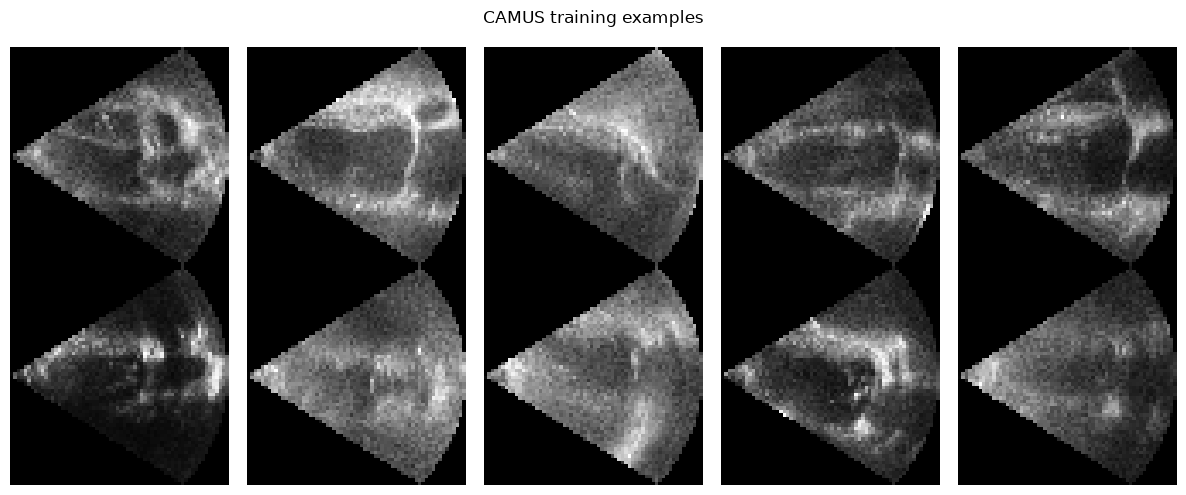

In [2]:
loaders = make_loaders(splits, batch_size=16)
batch = next(iter(loaders['train']))
print('batch shape:', tuple(batch.shape), 'range:', (float(batch.min()), float(batch.max())))
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for image, axis in zip(batch[:10], axes.flat):
    axis.imshow(image[0], cmap='gray')
    axis.axis('off')
fig.suptitle('CAMUS training examples')
plt.tight_layout()


## 2. Models and objective

The AE minimizes mean squared reconstruction error. The VAE uses the same encoder/decoder capacity but predicts a mean and log-variance, samples a latent vector with the reparameterization trick, and adds a configurable KL divergence term. A small KL weight is used initially to avoid sacrificing reconstruction fidelity too early.


In [3]:
from camus_ae.models import ConvAutoencoder, ConvVAE

x = torch.rand(2, 1, 64, 64)
ae = ConvAutoencoder(latent_dim=32)
vae = ConvVAE(latent_dim=32)
print('AE output:', tuple(ae(x).shape))
reconstruction, mu, logvar = vae(x)
print('VAE output:', tuple(reconstruction.shape), tuple(mu.shape), tuple(logvar.shape))


AE output: (2, 1, 64, 64)
VAE output: (2, 1, 64, 64) (2, 32) (2, 32)


## 3. Experiments

Run these commands from the repository root. Each experiment saves `config.json`, `history.json`, and the best checkpoint in its own directory. The trainer reloads the best validation checkpoint and evaluates it on the held-out test patients; `history.json` contains both validation and test reconstruction losses.

```powershell
python -m camus_ae.cli --model ae --output-dir outputs/ae_baseline --epochs 10
python -m camus_ae.cli --model vae --output-dir outputs/vae_baseline --epochs 10 --kl-weight 0.0001
```

Later iterations should change one factor at a time: latent dimension, KL weight, augmentation, or a perceptual/adversarial term. The same patient split must be retained for a fair comparison.


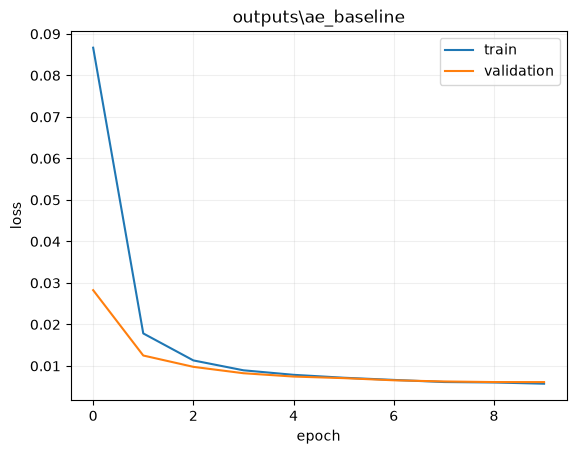

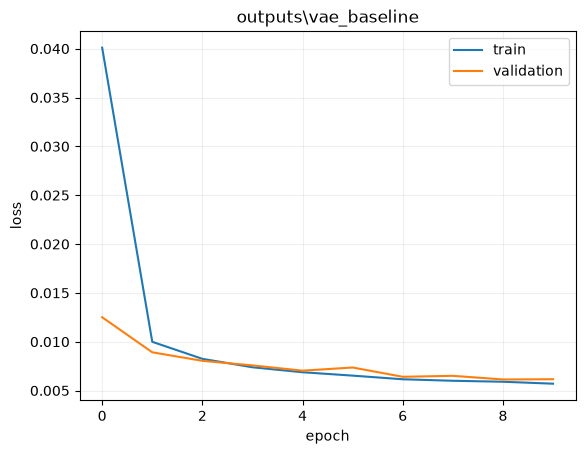

In [7]:
def show_history(path):
    history_path = Path(path) / 'history.json'
    if not history_path.exists():
        print(f'No results found at {history_path}; run the CLI commands above first.')
        return
    history = json.loads(history_path.read_text())
    plt.plot(history['train_loss'], label='train')
    plt.plot(history['val_loss'], label='validation')
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.legend()
    plt.grid(alpha=.2)
    plt.title(path)
    plt.show()


for output in Path('outputs').iterdir():
    if output.is_dir():
        show_history(output)

## 4. Interpretation and limitations

Validation reconstruction MSE is the main quantitative measure, but reconstruction grids are needed to identify blur, missing boundaries, or intensity artifacts. Patient-level splitting prevents leakage. The first version does not use segmentation masks as targets, keeping the comparison focused on unsupervised reconstruction. Future work can measure anatomical fidelity against the masks and compare augmentation, perceptual, or adversarial objectives.
